In [ ]:
# 1. Import libraries
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import joblib

print("Libraries imported successfully!")

Libraries imported successfully!


In [ ]:
# 2. Load the dataset
# In Google Colab, upload car_speed_synthetic_20000.csv when prompted.
DATA_FILE = "/content/car_speed_synthetic_20000.csv"

if not os.path.exists(DATA_FILE):
    try:
        from google.colab import files
        print("Upload the file: car_speed_synthetic_20000.csv")
        uploaded = files.upload()
        if DATA_FILE not in uploaded and not os.path.exists(DATA_FILE):
            raise FileNotFoundError(f"Please upload {DATA_FILE}")
    except ImportError:
        # Local fallback for environments where the CSV is beside the notebook
        if not os.path.exists(DATA_FILE):
            raise FileNotFoundError(f"Place {DATA_FILE} in the notebook's working folder.")

df = pd.read_csv(DATA_FILE)
print("Dataset loaded successfully!")
print(f"Rows: {df.shape[0]:,} | Columns: {df.shape[1]}")
display(df.head())

Dataset loaded successfully!
Rows: 20,000 | Columns: 14


,record_id,vehicle_speed_kph,engine_rpm,throttle_pos_percent,engine_load_percent,brake_pressure_percent,gear,road_slope_percent,acceleration_mps2,fuel_rate_lph,vehicle_mass_kg,ambient_temp_c,trip_distance_km,data_type
0,1,52.85,4061,38.48,34.71,3.64,4,-2.44,1.056,4.28,1404.2,40.9,0.001,synthetic_demo
1,2,52.26,3507,47.35,48.41,5.99,6,4.89,0.625,5.63,1674.4,24.7,0.003,synthetic_demo
2,3,67.75,4068,58.74,54.61,10.82,3,-10.00,1.239,5.33,1248.5,27.4,0.005,synthetic_demo
3,4,61.16,4834,47.02,41.80,2.72,5,-4.39,2.622,4.81,1287.2,30.2,0.007,synthetic_demo
4,5,64.67,4943,62.94,47.46,13.23,3,-0.43,2.630,4.98,1572.2,26.4,0.008,synthetic_demo


In [ ]:
# 3. Inspect dataset
print("Dataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())
print("\nData types and non-null counts:")
df.info()
print("\nStatistical summary:")
# display(df.describe(include="all").T)

Dataset shape: (20000, 14)

Column names:
['record_id', 'vehicle_speed_kph', 'engine_rpm', 'throttle_pos_percent', 'engine_load_percent', 'brake_pressure_percent', 'gear', 'road_slope_percent', 'acceleration_mps2', 'fuel_rate_lph', 'vehicle_mass_kg', 'ambient_temp_c', 'trip_distance_km', 'data_type']

Data types and non-null counts:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20000 entries, 0 to 19999
Data columns (total 14 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   record_id               20000 non-null  int64  
 1   vehicle_speed_kph       20000 non-null  float64
 2   engine_rpm              20000 non-null  int64  
 3   throttle_pos_percent    20000 non-null  float64
 4   engine_load_percent     20000 non-null  float64
 5   brake_pressure_percent  20000 non-null  float64
 6   gear                    20000 non-null  int64  
 7   road_slope_percent      20000 non-null  float64
 8   acceleration_mps2    

In [ ]:
# 4. Check and clean data quality
print("Missing values per column:")
print(df.isnull().sum())
print("\nDuplicate rows:", df.duplicated().sum())

df_clean = df.drop_duplicates().copy()

# Keep only rows with the target and selected model features present
features = [
    "engine_rpm",
    "throttle_pos_percent",
    "brake_pressure_percent",
    "engine_load_percent",
    "gear",
    "road_slope_percent"
]
target = "vehicle_speed_kph"
required_columns = features + [target]
missing_columns = [col for col in required_columns if col not in df_clean.columns]
if missing_columns:
    raise ValueError(f"Dataset is missing required columns: {missing_columns}")

df_clean = df_clean.dropna(subset=required_columns).copy()
print("Original shape:", df.shape)
print("Cleaned shape:", df_clean.shape)

Missing values per column:
record_id                 0
vehicle_speed_kph         0
engine_rpm                0
throttle_pos_percent      0
engine_load_percent       0
brake_pressure_percent    0
gear                      0
road_slope_percent        0
acceleration_mps2         0
fuel_rate_lph             0
vehicle_mass_kg           0
ambient_temp_c            0
trip_distance_km          0
data_type                 0
dtype: int64

Duplicate rows: 0
Original shape: (20000, 14)
Cleaned shape: (20000, 14)


In [ ]:
X = df_clean[features]
y = df_clean[target]

print("Input feature shape:", X.shape)
print("Target shape:", y.shape)
display(X.head())

Input feature shape: (20000, 6)
Target shape: (20000,)


,engine_rpm,throttle_pos_percent,brake_pressure_percent,engine_load_percent,gear,road_slope_percent
0,4061,38.48,3.64,34.71,4,-2.44
1,3507,47.35,5.99,48.41,6,4.89
2,4068,58.74,10.82,54.61,3,-10.00
3,4834,47.02,2.72,41.80,5,-4.39
4,4943,62.94,13.23,47.46,3,-0.43


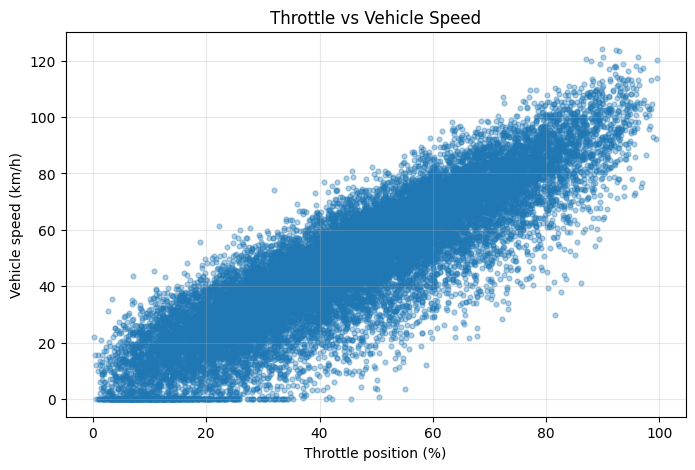

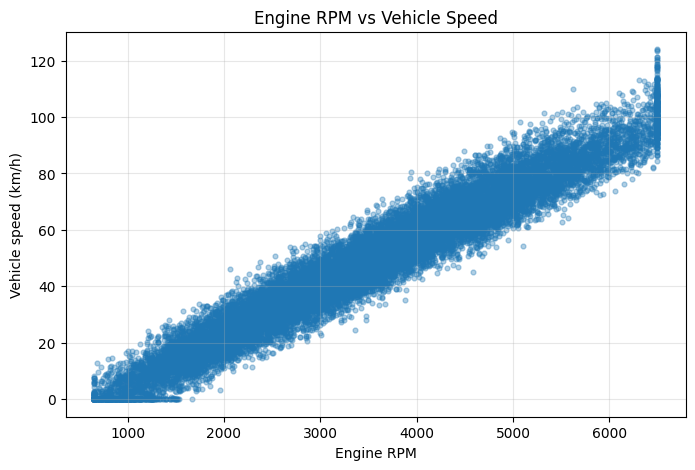

In [ ]:
# 6. Visualize important relationships
plt.figure(figsize=(8, 5))
plt.scatter(df_clean["throttle_pos_percent"], df_clean[target], alpha=0.35, s=12)
plt.xlabel("Throttle position (%)")
plt.ylabel("Vehicle speed (km/h)")
plt.title("Throttle vs Vehicle Speed")
plt.grid(True, alpha=0.3)
plt.show()

plt.figure(figsize=(8, 5))
plt.scatter(df_clean["engine_rpm"], df_clean[target], alpha=0.35, s=12)
plt.xlabel("Engine RPM")
plt.ylabel("Vehicle speed (km/h)")
plt.title("Engine RPM vs Vehicle Speed")
plt.grid(True, alpha=0.3)
plt.show()

In [ ]:
# 7. Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)
print(f"Training samples: {len(X_train):,}")
print(f"Testing samples:  {len(X_test):,}")

Training samples: 16,000
Testing samples:  4,000


In [ ]:
# 8. Train Linear Regression model
model = LinearRegression()
model.fit(X_train, y_train)
print("Linear Regression model trained successfully!")

Linear Regression model trained successfully!


In [ ]:
# 9. Inspect learned coefficients
coefficients = pd.DataFrame({
    "Feature": features,
    "Coefficient": model.coef_
}).sort_values("Coefficient", key=abs, ascending=False)
print("Intercept:", round(float(model.intercept_), 4))
display(coefficients)



Intercept: -2.3341


,Feature,Coefficient
4,gear,-0.733496
1,throttle_pos_percent,0.308398
2,brake_pressure_percent,-0.293342
5,road_slope_percent,-0.204752
3,engine_load_percent,-0.014107
0,engine_rpm,0.012577


In [ ]:
# 10. Predict on the test set
y_pred = model.predict(X_test)
comparison = pd.DataFrame({
    "Actual speed (km/h)": y_test.to_numpy(),
    "Predicted speed (km/h)": y_pred.round(2),
    "Absolute error (km/h)": np.abs(y_test.to_numpy() - y_pred).round(2)
})
display(comparison.head(15))

,Actual speed (km/h),Predicted speed (km/h),Absolute error (km/h)
0,18.19,19.67,1.48
1,78.41,73.68,4.73
2,36.22,45.17,8.95
3,58.08,55.08,3.00
4,8.90,13.98,5.08
5,32.76,31.63,1.13
6,19.13,15.42,3.71
7,33.61,27.54,6.07
8,20.43,15.81,4.62
9,85.53,85.07,0.46


In [ ]:
# 11. Evaluate model performance
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print(f"MAE  : {mae:.2f} km/h")
print(f"MSE  : {mse:.2f}")
print(f"RMSE : {rmse:.2f} km/h")
print(f"R²   : {r2:.4f}")
print("\nInterpretation:")
print("MAE/RMSE lower is better; R² closer to 1 indicates a better fit on this test split.")
print("These metrics describe this synthetic dataset only, not real-world driving accuracy.")

MAE  : 3.65 km/h
MSE  : 21.17
RMSE : 4.60 km/h
R²   : 0.9647

Interpretation:
MAE/RMSE lower is better; R² closer to 1 indicates a better fit on this test split.
These metrics describe this synthetic dataset only, not real-world driving accuracy.


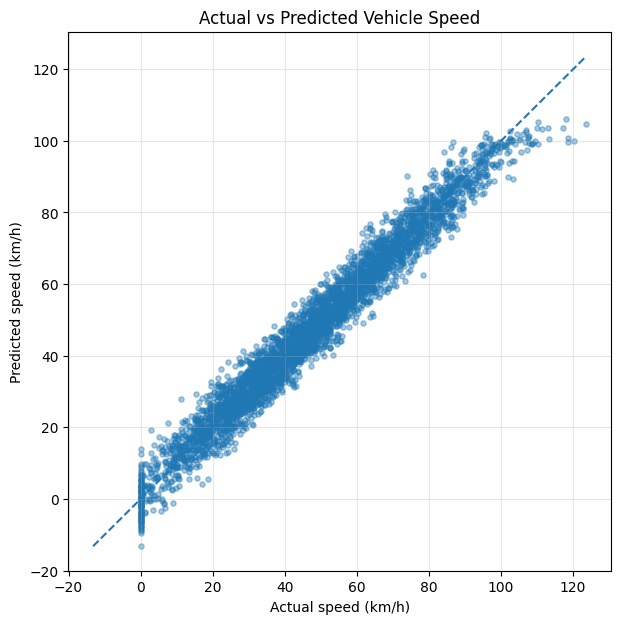

In [ ]:
# 12. Actual vs predicted graph
plt.figure(figsize=(7, 7))
plt.scatter(y_test, y_pred, alpha=0.4, s=14)
low = min(float(y_test.min()), float(np.min(y_pred)))
high = max(float(y_test.max()), float(np.max(y_pred)))
plt.plot([low, high], [low, high], linestyle="--")
plt.xlabel("Actual speed (km/h)")
plt.ylabel("Predicted speed (km/h)")
plt.title("Actual vs Predicted Vehicle Speed")
plt.grid(True, alpha=0.3)
plt.show()

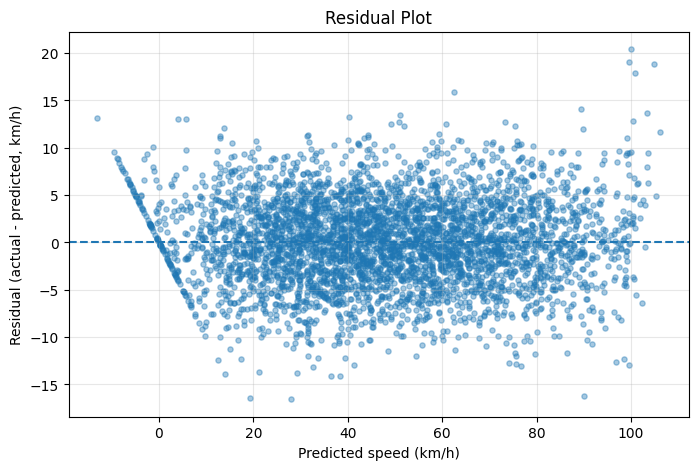

In [ ]:
# 13. Residual error graph
residuals = y_test.to_numpy() - y_pred
plt.figure(figsize=(8, 5))
plt.scatter(y_pred, residuals, alpha=0.4, s=14)
plt.axhline(0, linestyle="--")
plt.xlabel("Predicted speed (km/h)")
plt.ylabel("Residual (actual - predicted, km/h)")
plt.title("Residual Plot")
plt.grid(True, alpha=0.3)
plt.show()

In [ ]:
# 14. Try a prediction with example driving inputs
example = pd.DataFrame([{
    "engine_rpm": 3000,
    "throttle_pos_percent": 45,
    "brake_pressure_percent": 0,
    "engine_load_percent": 42,
    "gear": 4,
    "road_slope_percent": 1.5
}])[features]
example_prediction = model.predict(example)[0]
print("Example inputs:")
display(example)
print(f"Predicted vehicle speed: {example_prediction:.2f} km/h")
print("Demo prediction only — synthetic data model, not for real vehicle/safety use.")

Example inputs:


,engine_rpm,throttle_pos_percent,brake_pressure_percent,engine_load_percent,gear,road_slope_percent
0,3000,45,0,42,4,1.5


Predicted vehicle speed: 45.44 km/h
Demo prediction only — synthetic data model, not for real vehicle/safety use.


In [ ]:
import joblib
import sklearn

#save the train model
joblib.dump(model,"car_speed_linear_regression_model.pkl")

#check the installed scikit-learn version
print("scikit-learn version:",sklearn.__version__)

print("model saved successfully")

scikit-learn version: 1.6.1
model saved successfully


In [ ]:
from google.colab import files
files.download("car_speed_linear_regression_model.pkl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>